In [1]:
# imports
import os
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
dataset_path = "./datasets/Cifar10/cifar10/"

train_data_path = os.path.join(dataset_path , "train")
test_data_path = os.path.join(dataset_path , "test")

In [15]:
# create data loaders
train_data = tf.keras.utils.image_dataset_from_directory(
    train_data_path,
    image_size=(32, 32),
    batch_size=32,
    validation_split=0.2,
    subset="training",
    seed=42
)

validation_data = tf.keras.utils.image_dataset_from_directory(
    train_data_path,
    image_size=(32, 32),
    batch_size=32,
    validation_split=0.2,
    subset="validation",
    seed=42
)

test_data = tf.keras.utils.image_dataset_from_directory(test_data_path , image_size=(32,32) , batch_size=32)

Found 50000 files belonging to 10 classes.
Using 40000 files for training.
Found 50000 files belonging to 10 classes.
Using 10000 files for validation.
Found 10000 files belonging to 10 classes.


In [16]:
print("Classes:", train_data.class_names)

for images, labels in train_data.take(1):
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)

Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Image shape: (32, 32, 32, 3)
Label shape: (32,)


In [17]:
def visualize_samples():
    plt.figure(figsize=(10, 6))

    for images, labels in train_data.take(1):
        for i in range(10):
            plt.subplot(2, 5, i + 1)
            plt.imshow(images[i].numpy().astype("uint8"))
            plt.title(train_data.class_names[labels[i]])
            plt.axis("off")
    
    plt.tight_layout()
    plt.show()

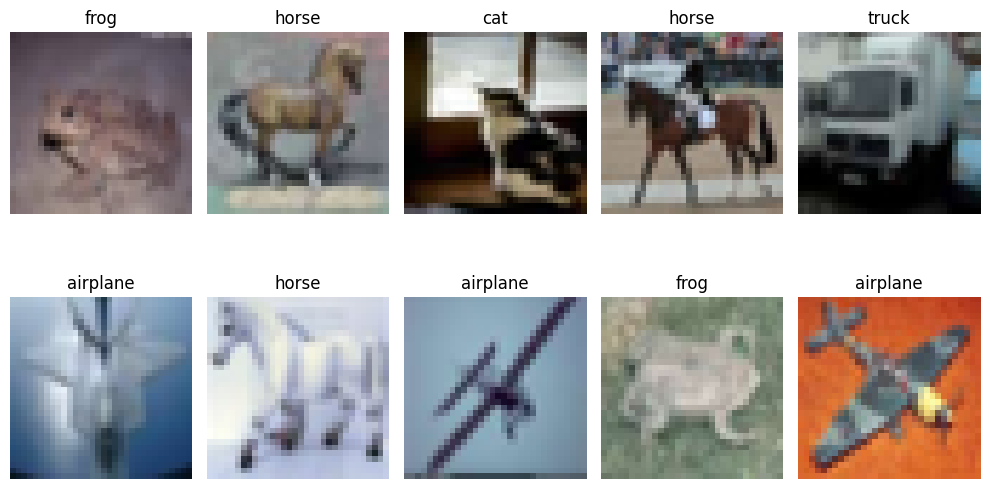

In [18]:
visualize_samples()

In [19]:
for images, labels in train_data.take(1):
    image = images[0]

    print("Image shape:", image.shape)
    print("Minimum pixel value:", image.numpy().min())
    print("Maximum pixel value:", image.numpy().max())
    print("Label:", labels[0].numpy())
    print("Class:", train_data.class_names[labels[0]])

Image shape: (32, 32, 3)
Minimum pixel value: 0.0
Maximum pixel value: 222.0
Label: 6
Class: frog


In [20]:
# build model

model = tf.keras.Sequential([
    
    tf.keras.layers.Rescaling(1./255),

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

In [21]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)              │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [22]:
# compile the cnn
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [25]:
history = model.fit(
    train_data,
    epochs=10,
    validation_data=validation_data
)

Epoch 1/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 17s 14ms/step - accuracy: 0.5363 - loss: 1.3042 - val_accuracy: 0.5875 - val_loss: 1.1778
Epoch 2/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 17s 13ms/step - accuracy: 0.6136 - loss: 1.1033 - val_accuracy: 0.6153 - val_loss: 1.0846
Epoch 3/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 17s 14ms/step - accuracy: 0.6549 - loss: 0.9928 - val_accuracy: 0.6312 - val_loss: 1.0408
Epoch 4/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 17s 14ms/step - accuracy: 0.6805 - loss: 0.9164 - val_accuracy: 0.6559 - val_loss: 0.9872
Epoch 5/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 17s 14ms/step - accuracy: 0.7018 - loss: 0.8558 - val_accuracy: 0.6567 - val_loss: 0.9799
Epoch 6/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 17s 14ms/step - accuracy: 0.7224 - loss: 0.8009 - val_accuracy: 0.6579 - val_loss: 0.9841
Epoch 7/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 17s 13ms/step - accuracy: 0.7391 - loss: 0.7514 - val_accuracy: 0.6705 - val_loss: 0.9469
Epoch 8/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 17s 13ms/step - accuracy: 0.7550 -

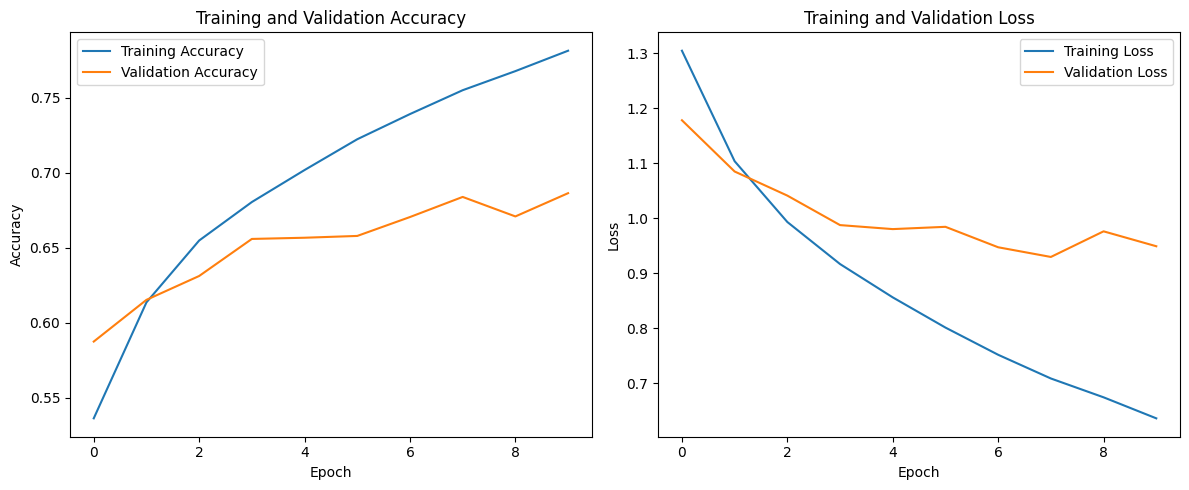

In [26]:
plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [27]:
print("Final Training Accuracy:",
      history.history["accuracy"][-1])

print("Final Validation Accuracy:",
      history.history["val_accuracy"][-1])

Final Training Accuracy: 0.7813500165939331
Final Validation Accuracy: 0.6863999962806702


In [28]:
test_loss, test_accuracy = model.evaluate(test_data)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6796 - loss: 0.9819
Test Loss: 0.9818686246871948
Test Accuracy: 0.6796000003814697


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step


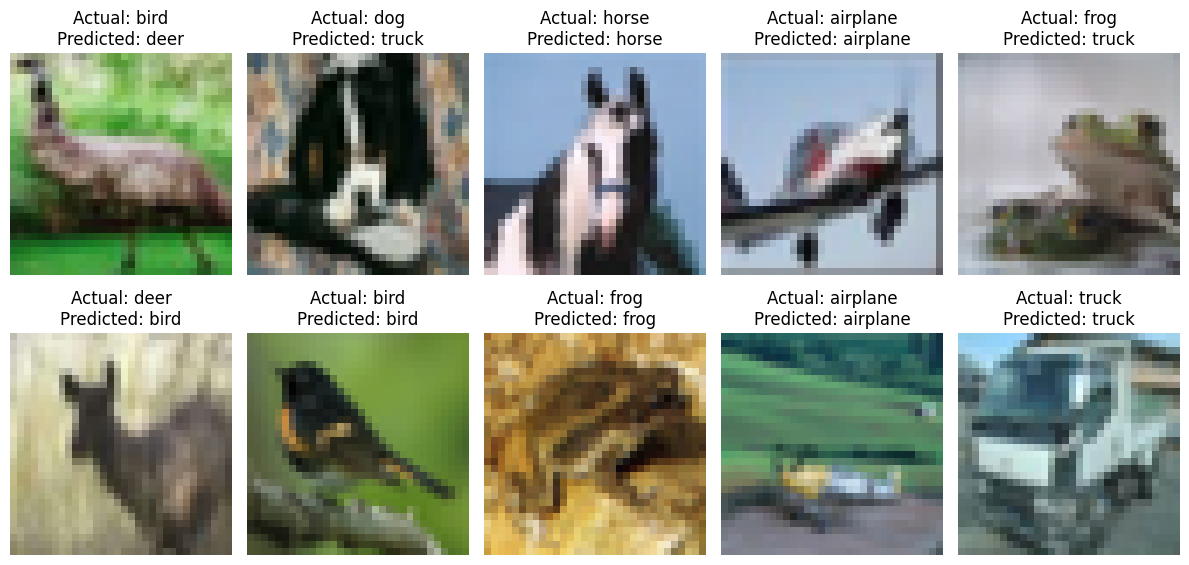

In [29]:
plt.figure(figsize=(12, 6))

for images, labels in test_data.take(1):

    predictions = model.predict(images)

    for i in range(10):
        predicted_class = np.argmax(predictions[i])

        plt.subplot(2, 5, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(
            f"Actual: {test_data.class_names[labels[i]]}\n"
            f"Predicted: {test_data.class_names[predicted_class]}"
        )

        plt.axis("off")

plt.tight_layout()
plt.show()